# HCES 2023–24 — Compact EDA (Fixed)

This notebook builds a household-level exploratory analysis from the four HCES 2023–24 CSV files. It uses local files; nothing needs to be uploaded.

**Important:** Run cells from top to bottom. The Level 15 loader prints the sections it actually reads and stops with a clear message if the expected expenditure sections are missing.

## 1. Imports and file paths

Keep this notebook in `C:\Users\anuja\Downloads\HCES_Project`, alongside the `HCES_2023_24` folder.

In [21]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path.cwd() / "HCES_2023_24"

L1 = DATA_DIR / "LEVEL - 01(Section 1 and 1_1).csv"
L3 = DATA_DIR / "LEVEL - 03.csv"
L5 = DATA_DIR / "LEVEL - 05 ( Sec 5  6).csv"
L15 = DATA_DIR / "LEVEL - 15 (Section 1_1, A2,B2  C2).csv"

for p in [L1, L3, L5, L15]:
    print(("FOUND  " if p.exists() else "MISSING"), p)

if not all(p.exists() for p in [L1, L3, L5, L15]):
    raise FileNotFoundError("One or more CSV paths are wrong. Check the printed paths and filenames.")

FOUND   c:\Users\anuja\Downloads\HCES_Project\HCES_2023_24\LEVEL - 01(Section 1 and 1_1).csv
FOUND   c:\Users\anuja\Downloads\HCES_Project\HCES_2023_24\LEVEL - 03.csv
FOUND   c:\Users\anuja\Downloads\HCES_Project\HCES_2023_24\LEVEL - 05 ( Sec 5  6).csv
FOUND   c:\Users\anuja\Downloads\HCES_Project\HCES_2023_24\LEVEL - 15 (Section 1_1, A2,B2  C2).csv


## 2. Load household files

Load identifiers as text to prevent key formatting mismatches.

In [22]:
l1 = pd.read_csv(L1, dtype=str, low_memory=False)
l3 = pd.read_csv(L3, dtype=str, low_memory=False)

print("Level 01 shape:", l1.shape)
print("Level 03 shape:", l3.shape)
print("Level 01 columns:", l1.columns.tolist())
print("Level 03 columns:", l3.columns.tolist())

Level 01 shape: (261953, 21)
Level 03 shape: (261953, 40)
Level 01 columns: ['Survey_Name', 'Year', 'FSU_Serial_No', 'Sector', 'State', 'NSS_Region', 'District', 'Stratum', 'Sub_stratum', 'Panel', 'Sub_sample', 'FOD_Sub_Region', 'Sample_SU_No', 'Sample_Sub_Division_No', 'Second_Stage_Stratum_No', 'Sample_Household_No', 'Questionnaire_No', 'Level', 'Survey_Code', 'Reason_for_Substitution_Code', 'Multiplier']
Level 03 columns: ['Survey_Name', 'Year', 'FSU_Serial_No', 'Sector', 'State', 'NSS_Region', 'District', 'Stratum', 'Sub_stratum', 'Panel', 'Sub_sample', 'FOD_Sub_Region', 'Sample_SU_No', 'Sample_Sub_Division_No', 'Second_Stage_Stratum_No', 'Sample_Household_No', 'Questionnaire_No', 'Level', 'HH_Size_FDQ', 'Engaged_in_Economic_Activity_Las', 'NCO_2015_Code', 'NIC_2008_Code', 'Max_Income_Activity', 'Self_Employment_Source_Sector', 'Regular_Wage_Source_Sector', 'Casual_Labour_Source_Sector', 'Household_Type', 'Religion_of_HH_Head', 'Social_Group_of_HH_Head', 'Land_Ownership', 'Type_of_

## 3. Load Level 15 and verify sections

This is the critical fix. It reads the exact Level 15 path, normalizes column names and section labels, and prints the section distribution **before** any filtering. If only section `11` appears, the notebook stops here so the wrong/partial file is not silently used.

In [23]:
l15 = pd.read_csv(L15, dtype=str, low_memory=False, encoding="utf-8-sig")

# Remove accidental spaces around headers and values
l15.columns = l15.columns.astype(str).str.strip()
if "SECTION" not in l15.columns:
    # tolerate lower-case/mixed-case header spelling
    section_candidates = [c for c in l15.columns if c.strip().upper() == "SECTION"]
    if section_candidates:
        l15 = l15.rename(columns={section_candidates[0]: "SECTION"})

if "SECTION" not in l15.columns:
    raise KeyError(f"No SECTION column found. Columns are: {l15.columns.tolist()}")

l15["SECTION"] = l15["SECTION"].astype(str).str.strip().str.upper()

print("Level 15 file:", L15.resolve())
print("Level 15 shape:", l15.shape)
print("Level 15 columns:", l15.columns.tolist())
print("\\nSection counts:")
print(l15["SECTION"].value_counts(dropna=False).to_string())

needed_sections = {"A2", "B2", "C2"}
found_sections = set(l15["SECTION"].dropna().unique())
if not needed_sections.issubset(found_sections):
    raise ValueError(
        "\\nExpected sections A2, B2, and C2 were not all found in this file. "
        "Do not continue yet. Check that this exact CSV is the complete Level 15 download, "
        "not an Excel-exported/filter-saved subset. "
        f"Sections found: {sorted(found_sections)}"
    )

Level 15 file: C:\Users\anuja\Downloads\HCES_Project\HCES_2023_24\LEVEL - 15 (Section 1_1, A2,B2  C2).csv
Level 15 shape: (1047812, 28)
Level 15 columns: ['Survey_Name', 'Year', 'FSU_Serial_No', 'Sector', 'State', 'NSS_Region', 'District', 'Stratum', 'Sub_stratum', 'Panel', 'Sub_sample', 'FOD_Sub_Region', 'Sample_SU_No', 'Sample_Sub_Division_No', 'Second_Stage_Stratum_No', 'Sample_Household_No', 'Questionnaire_No', 'VISIT', 'LEVEL', 'SECTION', 'TIME_TAKEN', 'MONTHLY_CONSUMPTION_EXP', 'ONLINE_EXPENDITURE', 'INFORMANT_CODE', 'RESPONSE_CODE', 'HOUSEHOLD_SIZE', 'VISIT_MONTH', 'MULTIPLIER']
\nSection counts:
SECTION
11    261953
A2    261953
B2    261953
C2    261953


## 4. Create household IDs and build the household table

In [24]:
KEYS = ["FSU_Serial_No", "Sample_Household_No"]

for name, df in [("Level 01", l1), ("Level 03", l3), ("Level 15", l15)]:
    missing = [c for c in KEYS if c not in df.columns]
    if missing:
        raise KeyError(f"{name} is missing key columns {missing}. Available columns: {df.columns.tolist()}")

for df in [l1, l3, l15]:
    df["HH_ID"] = df[KEYS].fillna("").astype(str).agg("_".join, axis=1)

hh = l1.drop_duplicates("HH_ID").copy()
hh = hh.merge(l3.drop_duplicates("HH_ID"), on="HH_ID", how="left", suffixes=("", "_L3"))

# Find household size column robustly
size_cols = [c for c in hh.columns if "HH" in c.upper() and "SIZE" in c.upper()]
if not size_cols:
    raise KeyError("Could not find a household-size column. Inspect the Level 03 columns printed above.")
size_col = next((c for c in size_cols if c.upper() == "HH_SIZE_"), size_cols[0])
print("Using household size column:", size_col)

hh["HH_SIZE"] = pd.to_numeric(hh[size_col], errors="coerce")
print("Household table shape:", hh.shape)
hh[["HH_ID", "HH_SIZE"]].head()

Using household size column: HH_Size_FDQ
Household table shape: (227114, 63)


,HH_ID,HH_SIZE
0,46667_01,5
1,46667_02,5
2,46667_03,5
3,46667_04,3
4,46667_05,5


## 5. Aggregate Level 15 monthly and online expenditure

The survey has repeated Level 15 rows by section. This code keeps A2/B2/C2 and aggregates them by household, after verifying those sections exist.

In [25]:

# Cell 5: Aggregate Level 15 expenditure correctly

# Keep only household questionnaire records
l15_exp = l15[
    l15["SECTION"].astype(str).str.strip().str.upper().isin(["A2", "B2", "C2"])
].copy()

print("Rows after section filter:", len(l15_exp))

# Aggregate expenditure by household ID
for col in ["MONTHLY_CONSUMPTION_EXP", "ONLINE_EXPENDITURE"]:
    l15_exp[col] = pd.to_numeric(l15_exp[col], errors="coerce")

spend = l15_exp.groupby("HH_ID", as_index=False).agg(
    MONTHLY_EXP=("MONTHLY_CONSUMPTION_EXP", "sum"),
    ONLINE_EXP=("ONLINE_EXPENDITURE", "sum")
)

# Merge with household table
hh = hh.drop(columns=["MONTHLY_EXP", "ONLINE_EXP"], errors="ignore")

hh = hh.merge(spend, on="HH_ID", how="left")

hh["PER_CAPITA_EXP"] = (
    hh["MONTHLY_EXP"] / hh["HH_SIZE"].replace(0, np.nan)
)

hh["ONLINE_FLAG"] = (hh["ONLINE_EXP"].fillna(0) > 0).astype(int)

hh["ONLINE_SHARE"] = (
    hh["ONLINE_EXP"] / hh["MONTHLY_EXP"].replace(0, np.nan)
)

print("Households with expenditure records:", spend["HH_ID"].nunique())
print(
    "Share matched:",
    round(hh["MONTHLY_EXP"].notna().mean() * 100, 2),
    "%"
)

display(
    hh[[
        "HH_SIZE", "MONTHLY_EXP", "ONLINE_EXP",
        "PER_CAPITA_EXP", "ONLINE_FLAG", "ONLINE_SHARE"
    ]].head(10)
)


Rows after section filter: 785859
Households with expenditure records: 227114
Share matched: 100.0 %


,HH_SIZE,MONTHLY_EXP,ONLINE_EXP,PER_CAPITA_EXP,ONLINE_FLAG,ONLINE_SHARE
0,5,126000.0,4100.0,25200.000000,1,0.032540
1,5,53000.0,0.0,10600.000000,0,0.000000
2,5,68000.0,2500.0,13600.000000,1,0.036765
3,3,45000.0,0.0,15000.000000,0,0.000000
4,5,50000.0,0.0,10000.000000,0,0.000000
5,3,48000.0,0.0,16000.000000,0,0.000000
6,4,61000.0,0.0,15250.000000,0,0.000000
7,3,55000.0,0.0,18333.333333,0,0.000000
8,3,72000.0,0.0,24000.000000,0,0.000000
9,6,57500.0,750.0,9583.333333,1,0.013043


In [26]:
# Check monthly expenditure distribution

print(
    hh["MONTHLY_EXP"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nTop 10 highest monthly expenditure households:")

display(
    hh.nlargest(10, "MONTHLY_EXP")[
        ["HH_ID", "HH_SIZE", "MONTHLY_EXP", "ONLINE_EXP", "PER_CAPITA_EXP"]
    ]
)

count    227114.000000
mean      44617.178122
std       35869.062728
min         600.000000
25%       24000.000000
50%       36000.000000
75%       52000.000000
90%       80000.000000
95%      108000.000000
99%      190800.000000
max      725000.000000
Name: MONTHLY_EXP, dtype: float64

Top 10 highest monthly expenditure households:


,HH_ID,HH_SIZE,MONTHLY_EXP,ONLINE_EXP,PER_CAPITA_EXP
185315,25866_01,5,725000.0,69400.0,145000.0
196236,29992_03,4,722000.0,23700.0,180500.0
185318,25866_04,4,677000.0,97000.0,169250.0
198129,29482_01,3,663000.0,20500.0,221000.0
185319,25866_05,10,641000.0,70500.0,64100.0
196237,29992_04,4,636000.0,16600.0,159000.0
173216,23163_01,10,611000.0,118913.0,61100.0
198133,29482_05,4,608000.0,21500.0,152000.0
138182,26926_01,4,601000.0,36910.0,150250.0
140024,26408_01,5,600000.0,151600.0,120000.0


## 6. Basic data quality

In [27]:
print("Household rows:", len(hh))
print("Duplicate HH_IDs:", hh["HH_ID"].duplicated().sum())
display(hh[["HH_SIZE", "MONTHLY_EXP", "ONLINE_EXP", "PER_CAPITA_EXP", "ONLINE_SHARE"]].isna().mean().mul(100).round(2).rename("missing_%").to_frame())
display(hh[["HH_SIZE", "MONTHLY_EXP", "ONLINE_EXP", "PER_CAPITA_EXP", "ONLINE_SHARE"]].describe().T)

Household rows: 227114
Duplicate HH_IDs: 0


,missing_%
HH_SIZE,0.0
MONTHLY_EXP,0.0
ONLINE_EXP,0.0
PER_CAPITA_EXP,0.0
ONLINE_SHARE,0.0


,count,mean,std,min,25%,50%,75%,max
HH_SIZE,227114.0,4.230404,2.078460,1.0,3.0,4.000000,5.000000,31.000000
MONTHLY_EXP,227114.0,44617.178122,35869.062728,600.0,24000.0,36000.000000,52000.000000,725000.000000
ONLINE_EXP,227114.0,2069.626060,5496.615736,0.0,0.0,150.000000,2000.000000,205000.000000
PER_CAPITA_EXP,227114.0,12368.591408,11634.895695,600.0,6187.5,9125.000000,14200.000000,356600.000000
ONLINE_SHARE,227114.0,0.035604,0.066953,0.0,0.0,0.003321,0.043053,0.947368


## 7. Monthly and per-capita expenditure distributions

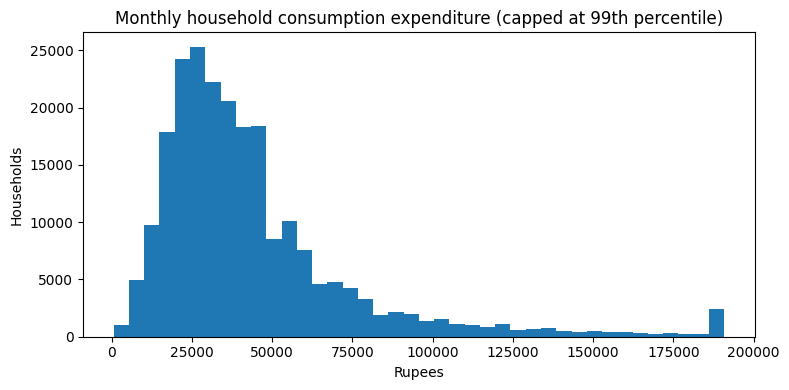

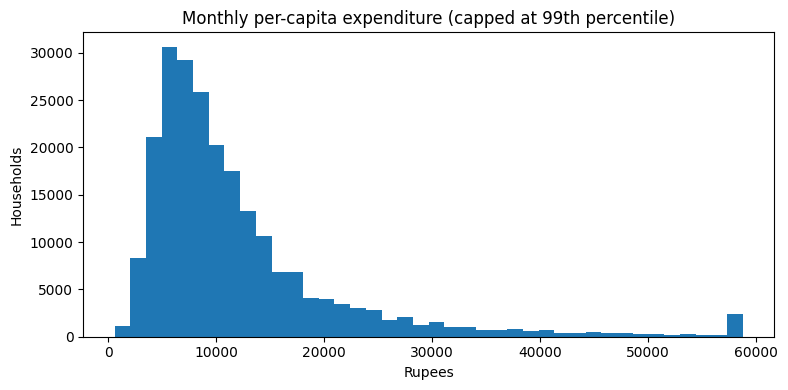

In [28]:
for col, title in [("MONTHLY_EXP", "Monthly household consumption expenditure"),
                   ("PER_CAPITA_EXP", "Monthly per-capita expenditure")]:
    x = hh[col].dropna()
    x = x[x >= 0]
    if len(x):
        plt.figure(figsize=(8, 4))
        plt.hist(x.clip(upper=x.quantile(0.99)), bins=40)
        plt.title(title + " (capped at 99th percentile)")
        plt.xlabel("Rupees")
        plt.ylabel("Households")
        plt.tight_layout()
        plt.show()

## 8. Rural/urban comparison

In [29]:
sector_col = next((c for c in hh.columns if c.upper() == "SECTOR"), None)
if sector_col:
    summary = hh.groupby(sector_col).agg(
        households=("HH_ID", "nunique"),
        median_monthly_exp=("MONTHLY_EXP", "median"),
        median_per_capita_exp=("PER_CAPITA_EXP", "median"),
        online_spend_rate=("ONLINE_FLAG", "mean")
    ).reset_index()
    summary["online_spend_rate"] *= 100
    display(summary)
else:
    print("SECTOR column not found; skipping rural/urban comparison.")

,Sector,households,median_monthly_exp,median_per_capita_exp,online_spend_rate
0,1,132790,32000.0,7750.0,38.666315
1,2,94324,42000.0,12000.0,66.691404


## 9. State-level comparison

In [30]:
state_col = next((c for c in hh.columns if c.upper() == "STATE"), None)
if state_col:
    state_summary = hh.groupby(state_col).agg(
        households=("HH_ID", "nunique"),
        median_monthly_exp=("MONTHLY_EXP", "median"),
        median_per_capita_exp=("PER_CAPITA_EXP", "median"),
        online_spend_rate=("ONLINE_FLAG", "mean")
    ).reset_index()
    state_summary["online_spend_rate"] *= 100
    display(state_summary.sort_values("median_per_capita_exp", ascending=False).head(15))
else:
    print("STATE column not found; skipping state comparison.")

,State,households,median_monthly_exp,median_per_capita_exp,online_spend_rate
32,34,947,53000.0,15666.666667,61.985216
3,04,578,54000.0,15500.000000,77.335640
33,35,857,51000.0,15333.333333,66.511085
12,13,2063,60000.0,15000.000000,90.159961
30,32,6099,48000.0,15000.000000,70.437777
28,30,559,56000.0,14050.000000,74.776386
34,36,6192,43600.0,13600.000000,65.810724
1,02,1867,39500.0,13570.000000,73.647563
5,06,4382,53000.0,13000.000000,58.534916
24,25,630,40900.0,12000.000000,42.539683


## 10. Online spending behavior

In [31]:
valid_online = hh[hh["MONTHLY_EXP"].gt(0)].copy()
print("Households with online expenditure > 0:", int((valid_online["ONLINE_EXP"].fillna(0) > 0).sum()))
print("Online spending rate among households with expenditure data:",
      round((valid_online["ONLINE_EXP"].fillna(0).gt(0).mean() * 100), 2), "%")

if not valid_online.empty:
    display(valid_online.groupby("ONLINE_FLAG").agg(
        households=("HH_ID", "nunique"),
        median_monthly_exp=("MONTHLY_EXP", "median"),
        median_per_capita_exp=("PER_CAPITA_EXP", "median"),
        median_online_exp=("ONLINE_EXP", "median")
    ).reset_index())

Households with online expenditure > 0: 114251
Online spending rate among households with expenditure data: 50.31 %


,ONLINE_FLAG,households,median_monthly_exp,median_per_capita_exp,median_online_exp
0,0,112863,28300.0,7560.0,0.0
1,1,114251,45000.0,11250.0,2000.0


## 11. Process Level 05 in chunks

Level 05 is very large, so read it in chunks and keep only the sampled household IDs. The sample is created below from Level 01.

In [32]:
sample_n = min(40000, hh["HH_ID"].nunique())
sample_ids = hh["HH_ID"].drop_duplicates().sample(n=sample_n, random_state=42)
sample_set = set(sample_ids)
print("Sampled households:", len(sample_set))

Sampled households: 40000


In [33]:
# Inspect Level 05 header first to avoid assuming exact column names
l5_header = pd.read_csv(L5, nrows=0)
l5_header.columns = l5_header.columns.astype(str).str.strip()
print("Level 05 columns:", l5_header.columns.tolist())

value_candidates = [c for c in l5_header.columns if "CONSUMPTION" in c.upper() and "VALUE" in c.upper()]
quantity_candidates = [c for c in l5_header.columns if "CONSUMPTION" in c.upper() and "QUANTITY" in c.upper()]
item_candidates = [c for c in l5_header.columns if c.strip().upper() == "ITEM_CODE"]

if not value_candidates:
    raise KeyError("Could not identify Level 05 consumption-value column. Use the printed columns to select it.")
if not item_candidates:
    raise KeyError("Could not identify Item_Code in Level 05. Use the printed columns to select it.")

value_col = value_candidates[0]
quantity_col = quantity_candidates[0] if quantity_candidates else None
item_col = item_candidates[0]
print("Using item/value/quantity columns:", item_col, value_col, quantity_col)

Level 05 columns: ['Survey_Name', 'Year', 'FSU_Serial_No', 'Sector', 'State', 'NSS_Region', 'District', 'Stratum', 'Sub_stratum', 'Panel', 'Sub_sample', 'FOD_Sub_Region', 'Sample_SU_No', 'Sample_Sub_Division_No', 'Second_Stage_Stratum_No', 'Sample_Household_No', 'Questionnaire_No', 'Level', 'Item_Code', 'OutOfHome_Consumption_Quantity', 'OutOfHome_Consumption_Value', 'Total_Consumption_Quantity', 'Total_Consumption_Value', 'Source', 'Multiplier']
Using item/value/quantity columns: Item_Code OutOfHome_Consumption_Value OutOfHome_Consumption_Quantity


In [34]:
parts = []
for chunk in pd.read_csv(L5, chunksize=300_000, dtype=str, low_memory=False):
    chunk.columns = chunk.columns.astype(str).str.strip()
    chunk["HH_ID"] = chunk[KEYS].fillna("").astype(str).agg("_".join, axis=1)
    chunk = chunk[chunk["HH_ID"].isin(sample_set)]
    if not chunk.empty:
        keep = ["HH_ID", item_col, value_col]
        if quantity_col:
            keep.append(quantity_col)
        parts.append(chunk[keep].copy())

if parts:
    cons = pd.concat(parts, ignore_index=True)
    cons[value_col] = pd.to_numeric(cons[value_col], errors="coerce")
    if quantity_col:
        cons[quantity_col] = pd.to_numeric(cons[quantity_col], errors="coerce")
        hh_cons = cons.groupby("HH_ID", as_index=False).agg(
            ITEM_CONSUMPTION_VALUE=(value_col, "sum"),
            ITEM_CONSUMPTION_QUANTITY=(quantity_col, "sum"),
            DISTINCT_ITEMS=(item_col, "nunique")
        )
    else:
        hh_cons = cons.groupby("HH_ID", as_index=False).agg(
            ITEM_CONSUMPTION_VALUE=(value_col, "sum"),
            DISTINCT_ITEMS=(item_col, "nunique")
        )
    hh_sample = hh[hh["HH_ID"].isin(sample_set)].merge(hh_cons, on="HH_ID", how="left")
    print("Sample item-level rows:", len(cons))
    print("Households with item records:", hh_cons["HH_ID"].nunique())
    display(hh_sample.head())
else:
    print("No Level 05 rows matched the sample IDs. Check household ID columns/formats across files.")

Sample item-level rows: 2238286
Households with item records: 39892


,Survey_Name,Year,FSU_Serial_No,Sector,State,NSS_Region,District,Stratum,Sub_stratum,Panel,...,Multiplier_L3,HH_SIZE,MONTHLY_EXP,ONLINE_EXP,PER_CAPITA_EXP,ONLINE_FLAG,ONLINE_SHARE,ITEM_CONSUMPTION_VALUE,ITEM_CONSUMPTION_QUANTITY,DISTINCT_ITEMS
0,HCES,2024,46667,1,01,012,06,13,01,2,...,24840,5,50000.0,0.0,10000.000000,0,0.000000,0.0,0.0,43.0
1,HCES,2024,46667,1,01,012,06,13,01,2,...,24840,4,61000.0,0.0,15250.000000,0,0.000000,0.0,0.0,48.0
2,HCES,2024,46667,1,01,012,06,13,01,2,...,24840,6,74000.0,750.0,12333.333333,1,0.010135,0.0,0.0,46.0
3,HCES,2024,46667,1,01,012,06,13,01,2,...,24840,4,56000.0,800.0,14000.000000,1,0.014286,0.0,0.0,46.0
4,HCES,2024,46663,1,01,012,06,13,01,3,...,17286,2,39000.0,0.0,19500.000000,0,0.000000,1380.0,30.1,34.0


## 12. Consumption breadth

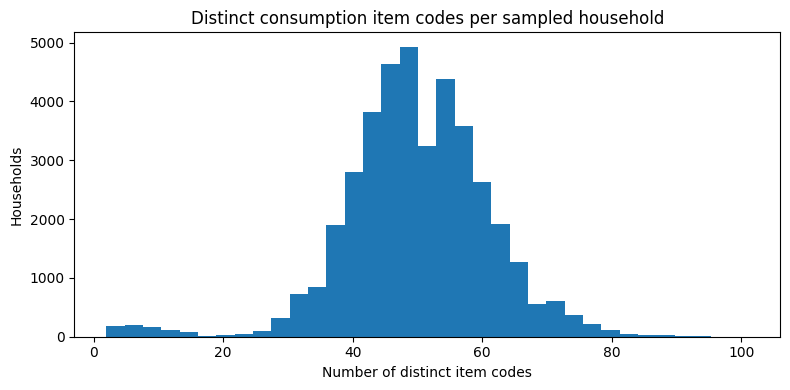

,MONTHLY_EXP,PER_CAPITA_EXP,DISTINCT_ITEMS
MONTHLY_EXP,1.000000,0.697969,0.427470
PER_CAPITA_EXP,0.697969,1.000000,0.164818
DISTINCT_ITEMS,0.427470,0.164818,1.000000


In [35]:
if "hh_sample" in globals() and "DISTINCT_ITEMS" in hh_sample.columns:
    plt.figure(figsize=(8, 4))
    plt.hist(hh_sample["DISTINCT_ITEMS"].dropna(), bins=35)
    plt.title("Distinct consumption item codes per sampled household")
    plt.xlabel("Number of distinct item codes")
    plt.ylabel("Households")
    plt.tight_layout()
    plt.show()
    display(hh_sample[["MONTHLY_EXP", "PER_CAPITA_EXP", "DISTINCT_ITEMS"]].corr(numeric_only=True))
else:
    print("Run the Level 05 processing cells successfully before this step.")

## 13. Export the household analysis table

In [36]:
out_path = Path.cwd() / "hces_household_eda_sample.csv"
hh.to_csv(out_path, index=False)
print("Saved household EDA table to:", out_path.resolve())

Saved household EDA table to: C:\Users\anuja\Downloads\HCES_Project\hces_household_eda_sample.csv


## Interpretation checklist

Before using the results in a portfolio:
- Explain that HCES is household survey data, not individual customer purchase history.
- Call the feature `online spending`, not proof of digital-payment adoption.
- Check the Level 15 section counts and merge rate before interpreting expenditure values.
- Consider the survey `Multiplier`/weight for population-level descriptive estimates. This notebook's basic summaries are unweighted.
- Treat segments as household consumption profiles, then turn them into testable FMCG/affordability/channel strategies.